# AI Exposure or Post-Pandemic Employment Adjustment? Explaining the Decline in Early-Career Hiring

## Author: Viet Nguyen

This is the main thesis notebook. The two Python files prepare the large source data; this notebook contains the research decisions, merge, diagnostics, figures, and models.

## Introduction

Generative artificial intelligence has created growing concern about how the labor market may change, especially for workers beginning their careers. Recent research has found weaker early-career hiring in industries with greater exposure to generative AI. However, a decline in hiring after 2022 does not necessarily mean that AI caused the decline. Some highly AI-exposed industries also experienced unusually strong employment growth during the COVID-19 pandemic, and their later reduction in hiring may partly reflect an adjustment from that earlier growth. Because these explanations can occur at the same time, it is important to consider post-pandemic employment adjustment when examining the relationship between AI exposure and early-career hiring.

This project asks: **After accounting for employment growth above pre-COVID trends, is greater generative AI exposure associated with a larger decline in hiring among workers ages 22 to 24?** To study this question, I combine quarterly hiring and employment data from the U.S. Census Bureau’s Quarterly Workforce Indicators with occupation-level AI exposure scores developed by Eloundou et al. I use pre-pandemic ACS PUMS employment data to translate the occupation-level scores into national industry-level exposure measures.

The study focuses on three main measures:

- **Early-career hiring**: the quarterly hiring rate for workers ages 22 to 24 within each state-industry group.
- **Generative AI exposure**: an industry-level measure of how much the occupations within an industry could potentially be affected by generative AI.
- **Employment above the pre-COVID predicted trend**: the percentage difference between actual employment in 2022 Q1 through Q3 and the employment predicted from each state-industry group’s 2015–2019 trend.

For the employment-trend measure, I estimate a separate pre-COVID trend for each state-industry group using all-age employment. The trend includes a linear time component and quarter indicators for regular seasonal differences. I then compare predicted employment with actual employment during the first three quarters of 2022. The main hiring analysis defines the post period as beginning in 2023 Q1 and excludes 2022 Q4 as a transition quarter.

This is an observational research project, so the results will be interpreted as associations rather than proof that generative AI caused changes in hiring. The AI-exposure measure represents the potential for workers’ tasks to be affected by generative AI; it does not measure whether firms actually adopted AI or replaced workers. Similarly, employment above its predicted trend does not prove that an industry overhired during the pandemic. The goal is to determine whether AI exposure remains associated with changes in early-career hiring after accounting for one measurable form of post-pandemic employment adjustment.

## Library Import

In [1]:
# Library imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from pyfixest.estimation.api.feols import feols
from statsmodels.graphics.gofplots import qqplot

## Data Preparation

For the data preparation part, I use two Python files: **qwi_pipeline.py** and **prepare_ai_exposure.py**. These programs handle the API requests and large-data processing that would be difficult to manage directly in a notebook. The first program downloads the Quarterly Workforce Indicators data from the U.S. Census Bureau. The second program uses ACS PUMS employment records and occupation-level AI exposure scores to create an industry-level AI exposure measure. The smaller prepared files are then loaded into the notebook, where I will check the data, construct the employment-trend measure, combine the research variables, and perform the analysis.

The **qwi_pipeline.py** program downloads quarterly hiring and employment data beginning in 2015 Q1. It collects observations for workers ages 22 to 24 and for workers of all ages. The younger age group is used to measure early-career hiring, while the all-ages group is used to estimate employment trends. The extraction is limited to private-sector employment, all sexes, unadjusted quarterly values, and the state-level jurisdictions with sufficient data. Alaska is excluded because its QWI series ends in 2016 Q2, and Michigan is excluded because its series ends in 2021 Q4. The program preserves the original Census responses, variable definitions, industry labels, and status flags before creating a cleaned three-digit industry file. Missing and Census-suppressed values remain missing rather than being replaced with zero.

The **prepare_ai_exposure.py** program creates the industry AI exposure measure. It reads the national 2015–2019 ACS PUMS person data and keeps employed private wage-and-salary workers. Workers are included when their employment-status code is 1 or 2 and their class-of-worker code is 1 or 2. Each person is weighted using the ACS person weight, `PWGTP`, so that the resulting occupation shares represent the national employed population rather than the number of survey records. The program then connects ACS occupation codes to the occupation-level GPT-4 beta exposure scores developed by Eloundou et al. Finally, it calculates a person-weighted average AI exposure score for each industry.

At first, I planned to construct the research data at the four-digit industry level. However, the ACS, occupation-exposure, and QWI files use different industry and occupation classifications. The ACS person data use 2017-based industry codes and 2018-based occupation codes, while the current QWI data use a newer industry classification. Some ACS codes connect to multiple possible industries or occupations with different AI exposure scores. Using these ambiguous matches would require assumptions that could create artificial precision in the final exposure measure.

To address this problem, I changed the working industry level from four digits to three digits and downloaded the three-digit QWI series directly from Census. I did not create three-digit hiring rates by averaging four-digit rates. The matching program only assigns an industry or occupation when the official crosswalk provides a clear link. An ACS occupation receives an AI exposure score only when its detailed occupation members lead to the same available exposure score. Ambiguous and unmatched records remain unassigned instead of receiving an invented score.

This conservative approach produces AI exposure estimates for 80 of the 96 three-digit industries in the QWI data. Approximately 42.2% of eligible ACS worker weight can be linked jointly to both a three-digit industry and a usable occupation exposure score. This coverage is an important limitation and will be reported in the analysis. The resulting industry scores measure potential exposure to generative AI based on the occupations employed within each industry; they do not measure whether firms actually adopted AI or whether workers were replaced.

The two programs produce the prepared QWI and industry-exposure files needed for the notebook. They do not estimate employment trends, create the final analysis panel, generate figures, or run statistical models. Those steps remain in the notebook so that each research decision, exclusion, diagnostic check, and result can be reviewed and explained clearly.


### Setup and input check

In [2]:
# Find the project root
project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / ".git").exists():
    project_root = project_root.parent

if not (project_root / ".git").exists():
    raise FileNotFoundError(
        "Open this notebook from inside the senior-research project."
    )

# Set data paths
qwi_path = project_root / "data/interim/qwi/qwi_research_ind3.csv"
exposure_path = (
    project_root
    / "data/interim/ai_exposure/industry_ai_exposure_3digit.csv"
)

# Check and preview the data
for path in (qwi_path, exposure_path):
    status = "FOUND" if path.exists() else "MISSING"
    print(status, path.relative_to(project_root))

qwi_preview = pd.read_csv(qwi_path, nrows=5)
exposure_preview = pd.read_csv(exposure_path, nrows=5)

display(qwi_preview)
display(exposure_preview)

FOUND data/interim/qwi/qwi_research_ind3.csv
FOUND data/interim/ai_exposure/industry_ai_exposure_3digit.csv


,Emp,EmpEnd,EmpTotal,HirA,HirAEnd,Sep,SepBeg,HirAEndR,SepBegR,sEmp,...,seasonadj,ind_level,state,year,quarter,period,state_name,age_group_name,ownership_name,industry_name
0,125,156,181,56,47,25,15,0.335,0.107,1,...,U,3,1,2015,1,2015Q1,Alabama,22-24,All Private,Crop Production
1,147,164,238,91,52,74,34,0.334,0.219,1,...,U,3,1,2015,2,2015Q2,Alabama,22-24,All Private,Crop Production
2,163,155,208,44,31,53,40,0.195,0.252,1,...,U,3,1,2015,3,2015Q3,Alabama,22-24,All Private,Crop Production
3,157,130,203,46,18,72,44,0.125,0.307,1,...,U,3,1,2015,4,2015Q4,Alabama,22-24,All Private,Crop Production
4,130,161,195,64,47,34,17,0.323,0.117,1,...,U,3,1,2016,1,2016Q1,Alabama,22-24,All Private,Crop Production


,industry,industry_name,ai_exposure,ai_exposure_coverage,eligible_person_weight,matched_person_weight
0,111,Crop Production,0.331394,0.275380,745007.0,205160.0
1,112,Animal Production and Aquaculture,0.338967,0.293680,320236.0,94047.0
2,113,Forestry and Logging,0.290433,0.215166,68338.0,14704.0
3,114,"Fishing, Hunting and Trapping",0.147798,0.744731,21448.0,15973.0
4,115,Support Activities for Agriculture and Forestry,0.273636,0.407574,113675.0,46331.0


### Load data

In [3]:
# Preserve Census identifiers as text
qwi = pd.read_csv(
    qwi_path,
    dtype={
        "state": "string",
        "industry": "string",
        "agegrp": "string",
        "ownercode": "string",
        "sex": "string",
        "seasonadj": "string",
        "ind_level": "string",
        "time": "string",
        "period": "string",
    },
)

exposure = pd.read_csv(
    exposure_path,
    dtype={"industry": "string"},
)

print("QWI shape:", qwi.shape)
print("AI exposure shape:", exposure.shape)

QWI shape: (375068, 33)
AI exposure shape: (96, 6)


### QWI Data Check

The QWI dataset contains the hiring and employment measures used in this study. Before constructing the research variables, I check that the file contains the intended age groups, private-sector observations, three-digit industries, and unadjusted quarterly data. I also check the time coverage and confirm that each state-industry-age-quarter observation is unique. Missing values are counted but not removed because some QWI values are suppressed by Census.


In [4]:
# Confirm the QWI research selections
research_settings = {
    "ind_level": {"3"},
    "ownercode": {"A05"},
    "sex": {"0"},
    "seasonadj": {"U"},
    "agegrp": {"A00", "A03"},
}

for column, expected in research_settings.items():
    actual = set(qwi[column].dropna().unique())
    print(f"{column}: {sorted(actual)}")
    assert actual == expected, f"Unexpected values in {column}: {actual}"


# Check coverage
print("\nRows:", len(qwi))
print("States:", qwi["state"].nunique())
print("Industries:", qwi["industry"].nunique())
print("Period:", qwi["period"].min(), "to", qwi["period"].max())


# Check that each observation is unique
qwi_key = ["state", "industry", "agegrp", "period"]
duplicate_rows = qwi.duplicated(qwi_key, keep=False).sum()

print("Duplicate key rows:", duplicate_rows)
assert duplicate_rows == 0, "The QWI file contains duplicate observations."


# Check missing values in the main research measures
missing_summary = pd.DataFrame(
    {
        "variable": ["EmpEnd for all ages", "HirAEndR for ages 22–24"],
        "missing_rows": [
            qwi.loc[qwi["agegrp"] == "A00", "EmpEnd"].isna().sum(),
            qwi.loc[qwi["agegrp"] == "A03", "HirAEndR"].isna().sum(),
        ],
    }
)

display(missing_summary)

ind_level: ['3']
ownercode: ['A05']
sex: ['0']
seasonadj: ['U']
agegrp: ['A00', 'A03']

Rows: 375068
States: 49
Industries: 96
Period: 2015Q1 to 2025Q4
Duplicate key rows: 0


,variable,missing_rows
0,EmpEnd for all ages,8150
1,HirAEndR for ages 22–24,24848


### AI Exposure Data Check

The AI-exposure dataset converts occupation-level exposure scores into national industry-level measures using ACS PUMS employment shares and person weights. Before merging it with QWI, I check that each industry appears once, that the exposure and coverage measures fall between zero and one, and that the industry codes match the QWI data. Industries without a defensible exposure estimate remain missing rather than receiving an assumed value.

In [5]:
# Check required columns
required_exposure_columns = {
    "industry",
    "industry_name",
    "ai_exposure",
    "ai_exposure_coverage",
    "eligible_person_weight",
    "matched_person_weight",
}

missing_columns = required_exposure_columns - set(exposure.columns)
assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"


# Check industry identifiers
duplicate_industries = exposure.duplicated("industry", keep=False).sum()

print("Industries:", exposure["industry"].nunique())
print("Duplicate industries:", duplicate_industries)

assert duplicate_industries == 0


# Check that the industry codes match QWI
qwi_industries = set(qwi["industry"].dropna())
exposure_industries = set(exposure["industry"].dropna())

print("QWI industries without an exposure row:", qwi_industries - exposure_industries)
print("Exposure industries not found in QWI:", exposure_industries - qwi_industries)

assert qwi_industries == exposure_industries


# Check the exposure values
assert exposure["ai_exposure"].dropna().between(0, 1).all()
assert exposure["ai_exposure_coverage"].dropna().between(0, 1).all()

print("Industries with an exposure score:", exposure["ai_exposure"].notna().sum())
print("Industries without an exposure score:", exposure["ai_exposure"].isna().sum())


# Review exposure coverage
display(
    exposure[["ai_exposure", "ai_exposure_coverage"]].describe()
)


# Show industries without a usable exposure score
missing_exposure = exposure.loc[
    exposure["ai_exposure"].isna(),
    ["industry", "industry_name"],
]

display(missing_exposure)

Industries: 96
Duplicate industries: 0
QWI industries without an exposure row: set()
Exposure industries not found in QWI: set()
Industries with an exposure score: 80
Industries without an exposure score: 16


,ai_exposure,ai_exposure_coverage
count,80.000000,80.000000
mean,0.381802,0.535200
std,0.103529,0.165674
min,0.126677,0.193776
25%,0.316714,0.423280
50%,0.377806,0.507937
75%,0.441073,0.687894
max,0.655173,0.883031


,industry,industry_name
9,236,Construction of Buildings
10,237,Heavy and Civil Engineering Construction
11,238,Specialty Trade Contractors
62,521,Monetary Authorities-Central Bank
64,523,"Securities, Commodity Contracts, and Other Fin..."
66,525,"Funds, Trusts, and Other Financial Vehicles"
69,533,Lessors of Nonfinancial Intangible Assets (exc...
71,551,Management of Companies and Enterprises
88,921,"Executive, Legislative, and Other General Gove..."
89,922,"Justice, Public Order, and Safety Activities"


### Prepare the Employment-Trend Sample

The employment-above-trend measure is based on quarter-end employment for workers of all ages. For each state-industry group, I use 2015 Q1 through 2019 Q4 as the pre-COVID trend period and 2022 Q1 through Q3 as the comparison period. The primary sample requires at least 16 of the 20 pre-COVID observations, with usable observations across all five years and all four calendar quarters. It also requires usable employment in all three comparison quarters. Missing employment values are not replaced or interpolated.

In [6]:
trend_key = ["state", "industry"]

# Select the trend and comparison periods
pretrend = qwi.loc[
    (qwi["agegrp"] == "A00")
    & qwi["period"].between("2015Q1", "2019Q4")
].copy()

comparison_2022 = qwi.loc[
    (qwi["agegrp"] == "A00")
    & qwi["period"].isin(["2022Q1", "2022Q2", "2022Q3"])
].copy()


# Count usable pre-COVID observations
pretrend["usable_year"] = pretrend["year"].where(pretrend["EmpEnd"].notna())
pretrend["usable_quarter"] = pretrend["quarter"].where(
    pretrend["EmpEnd"].notna()
)

pretrend_coverage = (
    pretrend.groupby(trend_key)
    .agg(
        pretrend_observations=("EmpEnd", "count"),
        pretrend_years=("usable_year", "nunique"),
        pretrend_quarters=("usable_quarter", "nunique"),
    )
    .reset_index()
)


# Count usable 2022 comparison observations
comparison_coverage = (
    comparison_2022.groupby(trend_key)["EmpEnd"]
    .count()
    .rename("comparison_observations")
    .reset_index()
)


# Define the primary and complete-case samples
trend_eligibility = pretrend_coverage.merge(
    comparison_coverage,
    on=trend_key,
    how="outer",
).fillna(0)

trend_eligibility["eligible_primary"] = (
    (trend_eligibility["pretrend_observations"] >= 16)
    & (trend_eligibility["pretrend_years"] == 5)
    & (trend_eligibility["pretrend_quarters"] == 4)
    & (trend_eligibility["comparison_observations"] == 3)
)

trend_eligibility["eligible_complete"] = (
    (trend_eligibility["pretrend_observations"] == 20)
    & (trend_eligibility["comparison_observations"] == 3)
)

print("State-industry groups:", len(trend_eligibility))
print(
    "Eligible primary groups:",
    trend_eligibility["eligible_primary"].sum(),
)
print(
    "Eligible complete-case groups:",
    trend_eligibility["eligible_complete"].sum(),
)

display(trend_eligibility.head())

State-industry groups: 4371
Eligible primary groups: 4122
Eligible complete-case groups: 4110


,state,industry,pretrend_observations,pretrend_years,pretrend_quarters,comparison_observations,eligible_primary,eligible_complete
0,01,111,20.0,5.0,4.0,3.0,True,True
1,01,112,20.0,5.0,4.0,3.0,True,True
2,01,113,20.0,5.0,4.0,3.0,True,True
3,01,114,20.0,5.0,4.0,3.0,True,True
4,01,115,20.0,5.0,4.0,3.0,True,True


### Estimate Pre-COVID Employment Trends

For each eligible state-industry group, I estimate a separate linear regression using quarterly all-age employment from 2015 through 2019. The model estimates employment as a linear function of time plus calendar-quarter indicators. The time coefficient represents the average quarterly change in employment, while the quarter indicators control for regular seasonal differences. I then use these coefficients to predict employment in 2022 Q1 through Q3. Pandemic-period observations are not used to estimate the pre-COVID trend.

In [7]:
eligible_groups = trend_eligibility.loc[
    trend_eligibility["eligible_primary"],
    trend_key,
]

pretrend_model_data = (
    pretrend.merge(
        eligible_groups,
        on=trend_key,
        how="inner",
        validate="many_to_one",
    )
    .dropna(subset=["EmpEnd"])
    .copy()
)

comparison_model_data = (
    comparison_2022.merge(
        eligible_groups,
        on=trend_key,
        how="inner",
        validate="many_to_one",
    )
    .dropna(subset=["EmpEnd"])
    .copy()
)


# Create the model variables
for data in (pretrend_model_data, comparison_model_data):
    data["time_index"] = (
        (data["year"] - 2015) * 4
        + data["quarter"]
        - 1
    )
    data["quarter_season"] = data["quarter"].astype(str)
    data["employment"] = data["EmpEnd"].astype(float)


# Fit one trend model per state-industry group
comparison_groups = comparison_model_data.groupby(trend_key)
prediction_frames = []
diagnostic_rows = []

for group_id, historical_data in pretrend_model_data.groupby(trend_key):
    model = smf.ols(
        "employment ~ time_index + C(quarter_season)",
        data=historical_data,
    ).fit()

    comparison_data = comparison_groups.get_group(group_id).copy()
    comparison_data["predicted_employment"] = model.predict(
        comparison_data
    )

    prediction_frames.append(comparison_data)
    diagnostic_rows.append(
        {
            "state": group_id[0],
            "industry": group_id[1],
            "pretrend_observations": int(model.nobs),
            "trend_r_squared": model.rsquared,
        }
    )


trend_predictions = pd.concat(
    prediction_frames,
    ignore_index=True,
)

trend_diagnostics = pd.DataFrame(diagnostic_rows)

print("Trend models estimated:", len(trend_diagnostics))
print("Employment predictions:", len(trend_predictions))

display(trend_predictions.head())

Trend models estimated: 4122
Employment predictions: 12366


,Emp,EmpEnd,EmpTotal,HirA,HirAEnd,Sep,SepBeg,HirAEndR,SepBegR,sEmp,...,quarter,period,state_name,age_group_name,ownership_name,industry_name,time_index,quarter_season,employment,predicted_employment
0,2960.0,3089.0,3450.0,491.0,394.0,362.0,265.0,0.130,0.088,1,...,1,2022Q1,Alabama,All Ages (14-99),All Private,Crop Production,28,1,3089.0,3326.225
1,3086.0,3205.0,3746.0,660.0,447.0,541.0,328.0,0.142,0.104,1,...,2,2022Q2,Alabama,All Ages (14-99),All Private,Crop Production,29,2,3205.0,3431.225
2,3205.0,3058.0,3593.0,389.0,272.0,536.0,419.0,0.087,0.134,1,...,3,2022Q3,Alabama,All Ages (14-99),All Private,Crop Production,30,3,3058.0,3351.825
3,1943.0,1972.0,2213.0,270.0,205.0,241.0,176.0,0.105,0.090,1,...,1,2022Q1,Alabama,All Ages (14-99),All Private,Animal Production and Aquaculture,28,1,1972.0,2228.800
4,1972.0,2070.0,2345.0,373.0,295.0,275.0,197.0,0.146,0.097,1,...,2,2022Q2,Alabama,All Ages (14-99),All Private,Animal Production and Aquaculture,29,2,2070.0,2292.400


### Calculate Employment Above Trend

Before constructing the employment-above-trend measure, I verify that every eligible state-industry group has one valid prediction for each of the three comparison quarters. For each quarter, the linear estimate is `100 × (actual employment - predicted employment) / predicted employment`; I then average the three quarterly percentages within each group. Positive values indicate employment above the predicted pre-COVID trend, while negative values indicate employment below the predicted trend. Because employment cannot be negative, I exclude an entire group if any of its three linear predictions is nonpositive.

In [8]:
# Check prediction coverage
prediction_counts = (
    trend_predictions.groupby(trend_key)
    .agg(
        prediction_rows=("period", "size"),
        prediction_quarters=("period", "nunique"),
    )
)

assert prediction_counts["prediction_rows"].eq(3).all()
assert prediction_counts["prediction_quarters"].eq(3).all()


# Identify groups with invalid predictions
prediction_validity = (
    trend_predictions.groupby(trend_key)
    .agg(
        positive_prediction_quarters=(
            "predicted_employment",
            lambda values: values.gt(0).sum(),
        ),
        minimum_predicted_employment=(
            "predicted_employment",
            "min",
        ),
    )
    .reset_index()
)

prediction_validity["valid_predictions"] = (
    prediction_validity["positive_prediction_quarters"] == 3
)

invalid_trend_groups = prediction_validity.loc[
    ~prediction_validity["valid_predictions"]
].copy()

valid_trend_groups = prediction_validity.loc[
    prediction_validity["valid_predictions"],
    trend_key,
]


# Keep all three quarters only for valid groups
valid_trend_predictions = trend_predictions.merge(
    valid_trend_groups,
    on=trend_key,
    how="inner",
    validate="many_to_one",
)

print("Groups originally modeled:", len(prediction_validity))
print("Groups excluded for nonpositive predictions:", len(invalid_trend_groups))
print("Groups with valid predictions:", len(valid_trend_groups))

display(invalid_trend_groups.head())


# Calculate quarterly employment deviations
valid_trend_predictions["employment_deviation_pct"] = (
    (
        valid_trend_predictions["employment"]
        - valid_trend_predictions["predicted_employment"]
    )
    / valid_trend_predictions["predicted_employment"]
    * 100
)


# Average the three quarterly deviations
employment_trend = (
    valid_trend_predictions.groupby(trend_key)
    .agg(
        employment_above_trend_pct=(
            "employment_deviation_pct",
            "mean",
        ),
        average_actual_employment=(
            "employment",
            "mean",
        ),
        average_predicted_employment=(
            "predicted_employment",
            "mean",
        ),
        comparison_quarters=("period", "nunique"),
    )
    .reset_index()
    .merge(
        trend_diagnostics,
        on=trend_key,
        how="left",
        validate="one_to_one",
    )
)

assert employment_trend["comparison_quarters"].eq(3).all()

display(
    employment_trend[
        [
            "employment_above_trend_pct",
            "trend_r_squared",
            "pretrend_observations",
        ]
    ].describe()
)

Groups originally modeled: 4122
Groups excluded for nonpositive predictions: 33
Groups with valid predictions: 4089


,state,industry,positive_prediction_quarters,minimum_predicted_employment,valid_predictions
174,05,114,0,-3.575,False
262,06,211,0,-1850.625,False
292,06,425,0,-11994.675,False
303,06,482,0,-10.225,False
359,08,313,0,-15.150,False


,employment_above_trend_pct,trend_r_squared,pretrend_observations
count,4089.000000,4089.000000,4089.000000
mean,12.674193,0.690520,19.994620
std,224.981566,0.275562,0.118991
min,-90.401991,0.004516,16.000000
25%,-9.122987,0.507107,20.000000
50%,-1.939410,0.787359,20.000000
75%,5.712281,0.920786,20.000000
max,8288.964657,0.998459,20.000000


### Log-Linear Sensitivity Check

The linear trend can eventually cross zero when a group has a steep historical decline. I therefore estimate the same time trend and seasonal controls using the natural logarithm of employment. This specification treats the trend as a percentage change rather than a fixed number of jobs per quarter, which is appropriate because state-industry groups differ greatly in size. Exponentiating the prediction keeps predicted employment positive, and a smearing correction accounts for converting the logged prediction back to average employment in levels. This log-linear estimate is the primary employment-trend measure, while the linear estimate is retained as a sensitivity check.

In [9]:
# Employment must be positive before taking its logarithm
nonpositive_log_rows = pretrend_model_data.loc[
    pretrend_model_data["employment"] <= 0
]

print("Nonpositive pre-trend observations:", len(nonpositive_log_rows))
assert nonpositive_log_rows.empty


# Use the same sample and controls as the linear model
log_pretrend_data = pretrend_model_data.copy()
log_pretrend_data["log_employment"] = np.log(
    log_pretrend_data["employment"]
)

log_comparison_groups = comparison_model_data.groupby(trend_key)
log_prediction_frames = []
log_diagnostic_rows = []

for group_id, historical_data in log_pretrend_data.groupby(trend_key):
    log_model = smf.ols(
        "log_employment ~ time_index + C(quarter_season)",
        data=historical_data,
    ).fit()

    comparison_data = log_comparison_groups.get_group(group_id).copy()
    comparison_data["predicted_log_employment"] = log_model.predict(
        comparison_data
    )

    # Convert predictions to employment levels with a smearing correction
    smearing_factor = np.exp(log_model.resid).mean()
    comparison_data["predicted_employment_log"] = (
        np.exp(comparison_data["predicted_log_employment"])
        * smearing_factor
    )

    log_prediction_frames.append(comparison_data)
    log_diagnostic_rows.append(
        {
            "state": group_id[0],
            "industry": group_id[1],
            "log_pretrend_observations": int(log_model.nobs),
            "log_trend_r_squared": log_model.rsquared,
            "log_smearing_factor": smearing_factor,
        }
    )


log_trend_predictions = pd.concat(
    log_prediction_frames,
    ignore_index=True,
)

log_trend_diagnostics = pd.DataFrame(log_diagnostic_rows)

print("Log-linear models estimated:", len(log_trend_diagnostics))
print("Log-linear predictions:", len(log_trend_predictions))

Nonpositive pre-trend observations: 0
Log-linear models estimated: 4122
Log-linear predictions: 12366


### Calculate the Log-Linear Estimate

I verify that each group has three finite, positive predictions. I then calculate the same quarterly percentage difference used for the linear estimate and average it across 2022 Q1 through Q3. This makes the two trend measures directly comparable.

In [10]:
# Validate the log-linear predictions
log_prediction_counts = log_trend_predictions.groupby(trend_key).size()

assert log_prediction_counts.eq(3).all()
assert np.isfinite(
    log_trend_predictions["predicted_employment_log"]
).all()
assert log_trend_predictions["predicted_employment_log"].gt(0).all()

print("Log-linear groups:", len(log_prediction_counts))
print(
    "Nonpositive log-linear predictions:",
    log_trend_predictions["predicted_employment_log"].le(0).sum(),
)


# Calculate and average the three quarterly deviations
log_trend_predictions["log_employment_deviation_pct"] = (
    (
        log_trend_predictions["employment"]
        - log_trend_predictions["predicted_employment_log"]
    )
    / log_trend_predictions["predicted_employment_log"]
    * 100
)

log_employment_trend = (
    log_trend_predictions.groupby(trend_key)
    .agg(
        employment_above_trend_log_pct=(
            "log_employment_deviation_pct",
            "mean",
        ),
        average_actual_employment=("employment", "mean"),
        average_log_predicted_employment=(
            "predicted_employment_log",
            "mean",
        ),
        comparison_quarters=("period", "nunique"),
    )
    .reset_index()
    .merge(
        log_trend_diagnostics,
        on=trend_key,
        how="left",
        validate="one_to_one",
    )
)

assert log_employment_trend["comparison_quarters"].eq(3).all()

display(
    log_employment_trend[
        [
            "employment_above_trend_log_pct",
            "log_trend_r_squared",
            "log_pretrend_observations",
        ]
    ].describe()
)

Log-linear groups: 4122
Nonpositive log-linear predictions: 0


,employment_above_trend_log_pct,log_trend_r_squared,log_pretrend_observations
count,4122.000000,4122.000000,4122.000000
mean,0.841465,0.691231,19.993935
std,36.203538,0.275174,0.127363
min,-95.908464,0.004861,16.000000
25%,-10.471737,0.512101,20.000000
50%,-2.789859,0.786339,20.000000
75%,4.816689,0.921159,20.000000
max,812.585157,0.998421,20.000000


### Compare the Linear and Log-Linear Estimates

The comparison joins the two group-level estimates and reports their correlation and percentage-point differences. It also confirms whether the log-linear model recovers the groups excluded from the linear measure. The final tables identify useful cases for the next step, where I will graph the observed data and both fitted trends.

In [11]:
# Add readable labels for reviewing possible graph examples
group_labels = (
    comparison_model_data[
        trend_key + ["state_name", "industry_name"]
    ]
    .drop_duplicates(trend_key)
)

linear_trend_measure = employment_trend[
    trend_key + ["employment_above_trend_pct"]
].rename(
    columns={
        "employment_above_trend_pct": (
            "employment_above_trend_linear_pct"
        )
    }
)

trend_method_comparison = (
    log_employment_trend.merge(
        linear_trend_measure,
        on=trend_key,
        how="left",
        validate="one_to_one",
    )
    .merge(
        group_labels,
        on=trend_key,
        how="left",
        validate="one_to_one",
    )
)

trend_method_comparison["difference_pct_points"] = (
    trend_method_comparison["employment_above_trend_log_pct"]
    - trend_method_comparison["employment_above_trend_linear_pct"]
)

comparison_overlap = trend_method_comparison.dropna(
    subset=["employment_above_trend_linear_pct"]
)

recovered_invalid_groups = (
    invalid_trend_groups[trend_key]
    .merge(
        trend_method_comparison,
        on=trend_key,
        how="inner",
        validate="one_to_one",
    )
)

print("Groups estimated by log-linear model:", len(trend_method_comparison))
print("Groups available under both methods:", len(comparison_overlap))
print("Invalid linear groups recovered:", len(recovered_invalid_groups))
print(
    "Correlation between estimates:",
    comparison_overlap[
        [
            "employment_above_trend_linear_pct",
            "employment_above_trend_log_pct",
        ]
    ].corr().iloc[0, 1],
)

largest_method_differences = (
    comparison_overlap.assign(
        absolute_difference=lambda data: (
            data["difference_pct_points"].abs()
        )
    )
    .nlargest(10, "absolute_difference")
)

display(
    largest_method_differences[
        trend_key
        + [
            "state_name",
            "industry_name",
            "employment_above_trend_linear_pct",
            "employment_above_trend_log_pct",
            "difference_pct_points",
        ]
    ]
)

display(
    recovered_invalid_groups[
        trend_key
        + [
            "state_name",
            "industry_name",
            "employment_above_trend_log_pct",
        ]
    ].head(10)
)

Groups estimated by log-linear model: 4122
Groups available under both methods: 4089
Invalid linear groups recovered: 33
Correlation between estimates: 0.40371303569541345


,state,industry,state_name,industry_name,employment_above_trend_linear_pct,employment_above_trend_log_pct,difference_pct_points
2492,35,525,New Mexico,"Funds, Trusts, and Other Financial Vehicles",8288.964657,576.453719,-7712.510937
854,15,425,Hawaii,Wholesale Trade Agents and Brokers,7588.372872,55.476884,-7532.895988
535,10,336,Delaware,Transportation Equipment Manufacturing,6171.126284,10.303599,-6160.822685
2869,40,316,Oklahoma,Leather and Allied Product Manufacturing,3955.482009,96.316919,-3859.165090
3649,50,425,Vermont,Wholesale Trade Agents and Brokers,2414.645704,64.379769,-2350.265935
1930,29,114,Missouri,"Fishing, Hunting and Trapping",2369.995121,151.191515,-2218.803606
1962,29,425,Missouri,Wholesale Trade Agents and Brokers,1615.591507,57.729196,-1557.862311
176,05,211,Arkansas,Oil and Gas Extraction,1153.456706,27.856578,-1125.600129
2801,39,425,Ohio,Wholesale Trade Agents and Brokers,1099.266680,70.395162,-1028.871517
1590,24,213,Maryland,Support Activities for Mining,1125.374787,112.270836,-1013.103952


,state,industry,state_name,industry_name,employment_above_trend_log_pct
0,05,114,Arkansas,"Fishing, Hunting and Trapping",81.850599
1,06,211,California,Oil and Gas Extraction,113.741366
2,06,425,California,Wholesale Trade Agents and Brokers,107.773981
3,06,482,California,Rail Transportation,76.359663
4,08,313,Colorado,Textile Mills,109.646328
5,10,518,Delaware,"Computing Infrastructure Providers, Data Proce...",172.607868
6,11,493,District of Columbia,Warehousing and Storage,812.585157
7,12,211,Florida,Oil and Gas Extraction,92.380487
8,16,211,Idaho,Oil and Gas Extraction,202.936198
9,16,487,Idaho,Scenic and Sightseeing Transportation,280.089551


### Trend Specification Decision

The diagnostic results support using the log-linear estimate as the primary employment-above-trend measure. The linear specification assumes that employment changes by a fixed number of jobs each quarter. When a group had a strong pre-pandemic decline, extending that fixed decline into 2022 sometimes pushed predicted employment to zero or below. This occurred in 33 of the 4,122 eligible state-industry groups. Even among the remaining groups, a positive prediction close to zero created extremely large percentage differences because predicted employment is the denominator of the measure. The maximum linear estimate was approximately 8,289%, compared with approximately 813% under the log-linear specification.

The log-linear specification instead assumes that employment changes at a proportional rate. This is more suitable for this dataset because employment cannot be negative and state-industry groups differ greatly in size. It also retains all 4,122 eligible groups and produces a less extreme distribution. The median estimates remain similar across the methods: approximately -1.94% for the linear measure and -2.79% for the log-linear measure. However, their correlation is only 0.404, showing that the choice of trend specification matters for some groups, particularly in the tails of the distribution.

This decision concerns only the construction of the employment-above-trend control; it does not make the final hiring model log-linear. I use `employment_above_trend_log_pct` as the primary control and retain `employment_above_trend_linear_pct` for a sensitivity analysis. The specification was selected from the employment-trend diagnostics before estimating the final hiring model. I next graph typical and extreme groups to confirm that the log-linear trend follows a plausible path and to determine whether the remaining large deviations reflect genuine employment changes or unstable estimates from small industries.

### Select Examples for the Trend Diagnostic

I select three examples using reproducible rules. The typical case is close to the median log-linear estimate and has similar estimates under both methods. The disagreement case has the largest difference between valid linear and log-linear estimates. The invalid-linear case has the largest absolute log-linear deviation among groups that received a nonpositive linear prediction. These cases are diagnostic examples and are not used to remove observations.

In [12]:
# Select a typical group near the median where the methods agree
log_trend_median = comparison_overlap[
    "employment_above_trend_log_pct"
].median()

comparison_for_selection = comparison_overlap.assign(
    typical_score=(
        comparison_overlap["employment_above_trend_log_pct"]
        .sub(log_trend_median)
        .abs()
        + comparison_overlap["difference_pct_points"].abs()
    ),
    absolute_method_difference=(
        comparison_overlap["difference_pct_points"].abs()
    ),
)

typical_case = (
    comparison_for_selection
    .sort_values(["typical_score", "state", "industry"])
    .head(1)
    .assign(diagnostic_case="Typical group")
)

largest_difference_case = (
    comparison_for_selection
    .sort_values(
        ["absolute_method_difference", "state", "industry"],
        ascending=[False, True, True],
    )
    .head(1)
    .assign(diagnostic_case="Largest method difference")
)

invalid_linear_case = (
    recovered_invalid_groups
    .assign(
        absolute_log_deviation=lambda data: (
            data["employment_above_trend_log_pct"].abs()
        )
    )
    .sort_values(
        ["absolute_log_deviation", "state", "industry"],
        ascending=[False, True, True],
    )
    .head(1)
    .assign(diagnostic_case="Invalid linear prediction")
)

diagnostic_groups = pd.concat(
    [typical_case, largest_difference_case, invalid_linear_case],
    ignore_index=True,
)

display(
    diagnostic_groups[
        [
            "diagnostic_case",
            "state",
            "state_name",
            "industry",
            "industry_name",
            "employment_above_trend_linear_pct",
            "employment_above_trend_log_pct",
        ]
    ]
)

,diagnostic_case,state,state_name,industry,industry_name,employment_above_trend_linear_pct,employment_above_trend_log_pct
0,Typical group,08,Colorado,332,Fabricated Metal Product Manufacturing,-2.861850,-2.917802
1,Largest method difference,35,New Mexico,525,"Funds, Trusts, and Other Financial Vehicles",8288.964657,576.453719
2,Invalid linear prediction,11,District of Columbia,493,Warehousing and Storage,NaN,812.585157


### Graph the Linear and Log-Linear Trends

The three graphs compare observed quarter-end employment with linear and log-linear trends estimated only from 2015 through 2019. The first graph shows a typical group where the two methods produce similar predictions. The second shows the largest difference among groups with valid predictions from both methods, and the third shows a group where the linear prediction falls below zero. The shaded area marks 2020 and 2021, which are excluded from trend estimation, while the open diamonds show actual employment during 2022 Q1 through Q3. Together, the graphs show why the log-linear specification provides a more plausible employment trend when linear extrapolation becomes unstable.

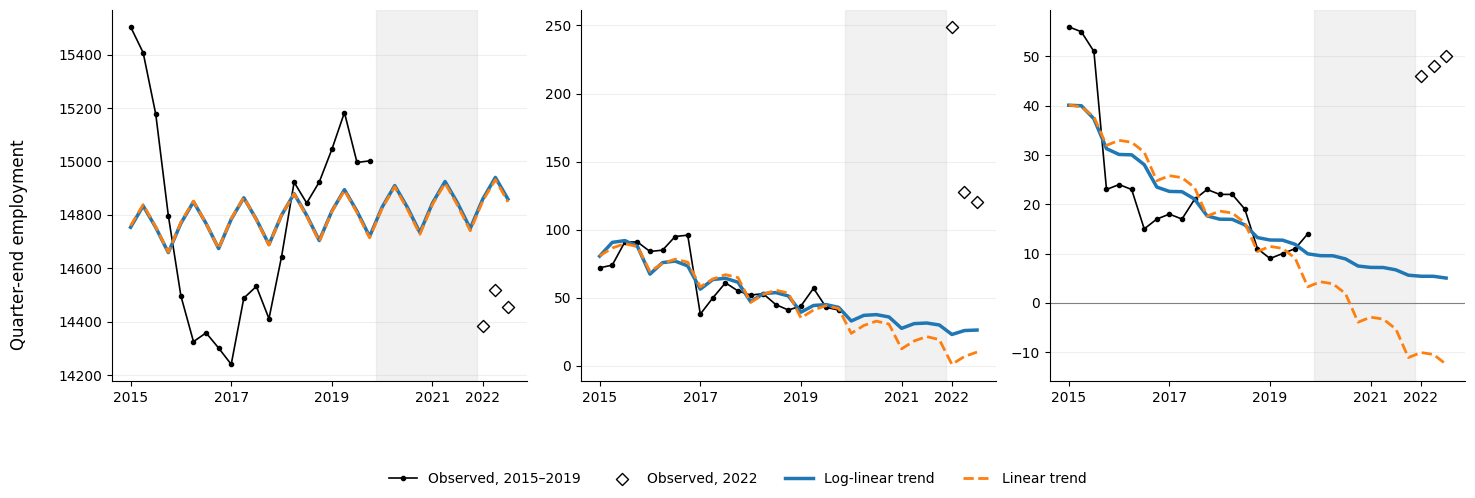

**Fig. 1. Log-Linear Employment Trends Remain Plausible When Linear Extrapolations Become Unstable.**

In [13]:
# Create a common quarterly prediction grid
prediction_grid = pd.DataFrame(
    {"time_index": np.arange(31)}
)

prediction_grid["quarter"] = (
    prediction_grid["time_index"] % 4 + 1
)

prediction_grid["quarter_season"] = (
    prediction_grid["quarter"].astype(str)
)


fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 5),
)


for ax, group in zip(
    axes,
    diagnostic_groups.itertuples(index=False),
):
    # Select the group's estimation data
    historical_filter = (
        (pretrend_model_data["state"] == group.state)
        & (pretrend_model_data["industry"] == group.industry)
    )

    comparison_filter = (
        (comparison_model_data["state"] == group.state)
        & (comparison_model_data["industry"] == group.industry)
    )

    historical = (
        pretrend_model_data.loc[historical_filter]
        .sort_values("time_index")
        .copy()
    )

    comparison = (
        comparison_model_data.loc[comparison_filter]
        .sort_values("time_index")
        .copy()
    )

    historical["log_employment"] = np.log(
        historical["employment"]
    )

    # Estimate both trends using the same observations
    linear_model = smf.ols(
        "employment ~ time_index + C(quarter_season)",
        data=historical,
    ).fit()

    log_model = smf.ols(
        "log_employment ~ time_index + C(quarter_season)",
        data=historical,
    ).fit()

    group_predictions = prediction_grid.copy()

    group_predictions["linear"] = linear_model.predict(
        group_predictions
    )

    smearing_factor = np.exp(log_model.resid).mean()

    group_predictions["log_linear"] = (
        np.exp(log_model.predict(group_predictions))
        * smearing_factor
    )

    # Mark the excluded pandemic period
    ax.axvspan(
        19.5,
        27.5,
        color="lightgray",
        alpha=0.3,
    )

    # Plot observed and predicted employment
    ax.plot(
        historical["time_index"],
        historical["employment"],
        color="black",
        marker="o",
        markersize=3,
        linewidth=1.2,
        label="Observed, 2015–2019",
    )

    ax.scatter(
        comparison["time_index"],
        comparison["employment"],
        facecolors="white",
        edgecolors="black",
        marker="D",
        s=38,
        zorder=4,
        label="Observed, 2022",
    )

    ax.plot(
        group_predictions["time_index"],
        group_predictions["log_linear"],
        color="tab:blue",
        linewidth=2.5,
        label="Log-linear trend",
        zorder=2,
    )

    ax.plot(
        group_predictions["time_index"],
        group_predictions["linear"],
        color="tab:orange",
        linestyle="--",
        linewidth=2,
        label="Linear trend",
        zorder=3,
    )

    # Zero is especially relevant for the invalid prediction
    if group.diagnostic_case == "Invalid linear prediction":
        ax.axhline(
            0,
            color="gray",
            linewidth=0.8,
        )

    ax.set_xticks(
        [0, 8, 16, 24, 28],
        ["2015", "2017", "2019", "2021", "2022"],
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.2)


fig.supxlabel("")
fig.supylabel("Quarter-end employment")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
)

fig.tight_layout(
    rect=(0.02, 0.12, 1, 1)
)

plt.show()
display(
    Markdown(
        "**Fig. 1. Log-Linear Employment Trends Remain Plausible When Linear Extrapolations Become Unstable.**"
    )
)

fig.savefig(project_root / "figures" / "employment_trend_comparison.png", dpi=300, bbox_inches="tight")

The first graph shows a typical case, Fabricated Metal Product Manufacturing in Colorado. The linear and log-linear trends are nearly identical, and both estimate that 2022 employment was about 2.9% below its predicted trend. This indicates that the choice of specification makes little difference for a typical state-industry group.

The second graph shows Funds, Trusts, and Other Financial Vehicles in New Mexico, where the methods differ substantially. The linear trend approaches zero by 2022, causing the percentage difference to rise to approximately 8,289% because predicted employment is the denominator. The log-linear model keeps predicted employment positive and produces a smaller, although still unusually large, estimate of approximately 576%. Both methods indicate employment above its pre-pandemic trend, but the linear magnitude is driven heavily by a near-zero prediction.

The third graph shows Warehousing and Storage in the District of Columbia. Extending its fixed linear decline produces a negative employment prediction, so a meaningful percentage difference cannot be calculated. The log-linear trend remains positive and estimates employment approximately 813% above trend. This demonstrates that the log-linear model resolves the mathematical problem of negative predictions, although the large remaining estimate still identifies this group as an extreme case that should be interpreted cautiously.

Overall, the graphs support using the log-linear specification because it behaves similarly to the linear model in a typical case while remaining positive and less sensitive to declining trends in problematic cases. The graphs do not prove that the log-linear counterfactual is correct, so the linear measure remains useful as a sensitivity check and the extreme log-linear observations should be examined in the later robustness analysis.

## Construct the Final Analysis Panel

The final panel combines the three main research measures. The outcome is the end-of-quarter hiring rate for workers ages 22 to 24. I convert the rate to percentage points for easier interpretation. Following the research design, the pre-2023 comparison period covers 2015 Q1 through 2022 Q3, the post-period begins in 2023 Q1, and 2022 Q4 is excluded as a transition quarter. The pandemic and early recovery quarters remain in the panel because quarter fixed effects will account for changes shared across state-industry groups in each quarter.

I merge AI exposure by industry and the employment-above-trend measures by state and industry. The log-linear measure is the primary employment control, while the linear measure is retained for sensitivity analysis. Missing hiring rates, unavailable AI scores, and unavailable employment trends are excluded transparently rather than replaced. Because the study compares hiring before and after the pandemic, the primary sample also requires each state-industry group to have at least one valid hiring observation in both periods.

In [14]:
panel_key = ["state", "industry", "period"]

# Select the early-career hiring observations
hiring_panel = qwi.loc[
    qwi["agegrp"] == "A03",
    [
        "state",
        "state_name",
        "industry",
        "industry_name",
        "period",
        "year",
        "quarter",
        "HirAEnd",
        "sHirAEnd",
        "HirAEndR",
        "sHirAEndR",
    ],
].rename(
    columns={
        "HirAEnd": "hire_count",
        "sHirAEnd": "hire_count_status",
        "HirAEndR": "hiring_rate",
        "sHirAEndR": "hiring_rate_status",
    }
).copy()

assert not hiring_panel.duplicated(panel_key).any()


# Prepare the two hiring outcomes
hiring_panel["hire_count"] = hiring_panel["hire_count"].astype(float)
hiring_panel["hiring_rate"] = hiring_panel["hiring_rate"].astype(float)
hiring_panel["hiring_rate_pct"] = (
    hiring_panel["hiring_rate"] * 100
)


# Define the pre, post, and excluded periods
pre_period = hiring_panel["period"].between(
    "2015Q1",
    "2022Q3",
)

post_period = hiring_panel["period"].ge("2023Q1")

hiring_panel["analysis_period"] = np.select(
    [pre_period, post_period],
    ["pre", "post"],
    default="excluded",
)

hiring_panel["post"] = (
    hiring_panel["analysis_period"]
    .map({"pre": 0, "post": 1})
    .astype("Int64")
)


# Keep only the variables needed from the other datasets
exposure_controls = exposure[
    [
        "industry",
        "ai_exposure",
        "ai_exposure_coverage",
    ]
].copy()

trend_controls = trend_method_comparison[
    trend_key
    + [
        "employment_above_trend_log_pct",
        "employment_above_trend_linear_pct",
    ]
].copy()


# Merge the research measures
analysis_panel = (
    hiring_panel
    .merge(
        exposure_controls,
        on="industry",
        how="left",
        validate="many_to_one",
    )
    .merge(
        trend_controls,
        on=trend_key,
        how="left",
        validate="many_to_one",
    )
)

assert not analysis_panel.duplicated(panel_key).any()


# Define the complete primary sample
complete_primary = (
    analysis_panel["analysis_period"].isin(["pre", "post"])
    & analysis_panel["hiring_rate_pct"].notna()
    & analysis_panel["ai_exposure"].notna()
    & analysis_panel["employment_above_trend_log_pct"].notna()
)

complete_case_panel = (
    analysis_panel.loc[complete_primary]
    .copy()
)

complete_case_panel["post"] = (
    complete_case_panel["post"].astype(int)
)


# Require each group to appear in both periods
candidate_group_coverage = (
    complete_case_panel
    .groupby(trend_key)
    .agg(
        pre_observations=(
            "post",
            lambda values: values.eq(0).sum(),
        ),
        post_observations=(
            "post",
            lambda values: values.eq(1).sum(),
        ),
    )
    .reset_index()
)

eligible_comparison_groups = candidate_group_coverage.loc[
    (candidate_group_coverage["pre_observations"] > 0)
    & (candidate_group_coverage["post_observations"] > 0),
    trend_key,
]

excluded_one_period_groups = candidate_group_coverage.loc[
    (candidate_group_coverage["pre_observations"] == 0)
    | (candidate_group_coverage["post_observations"] == 0)
].copy()

primary_analysis_panel = (
    complete_case_panel
    .merge(
        eligible_comparison_groups,
        on=trend_key,
        how="inner",
        validate="many_to_one",
    )
    .sort_values(
        ["state", "industry", "year", "quarter"]
    )
    .copy()
)


# The linear sensitivity sample excludes groups
# without valid linear predictions
linear_sensitivity_panel = (
    primary_analysis_panel
    .dropna(
        subset=["employment_above_trend_linear_pct"]
    )
    .copy()
)

print("Primary panel rows:", len(primary_analysis_panel))
print(
    "Linear sensitivity rows:",
    len(linear_sensitivity_panel),
)

display(primary_analysis_panel.head())

Primary panel rows: 145995
Linear sensitivity rows: 145328


,state,state_name,industry,industry_name,period,year,quarter,hire_count,hire_count_status,hiring_rate,hiring_rate_status,hiring_rate_pct,analysis_period,post,ai_exposure,ai_exposure_coverage,employment_above_trend_log_pct,employment_above_trend_linear_pct
0,01,Alabama,111,Crop Production,2015Q1,2015,1,47.0,1,0.335,6,33.5,pre,0,0.331394,0.27538,-7.57317,-7.497068
1,01,Alabama,111,Crop Production,2015Q2,2015,2,52.0,1,0.334,6,33.4,pre,0,0.331394,0.27538,-7.57317,-7.497068
2,01,Alabama,111,Crop Production,2015Q3,2015,3,31.0,1,0.195,6,19.5,pre,0,0.331394,0.27538,-7.57317,-7.497068
3,01,Alabama,111,Crop Production,2015Q4,2015,4,18.0,1,0.125,6,12.5,pre,0,0.331394,0.27538,-7.57317,-7.497068
4,01,Alabama,111,Crop Production,2016Q1,2016,1,47.0,1,0.323,6,32.3,pre,0,0.331394,0.27538,-7.57317,-7.497068


### Check the Final Analysis Panel

The following checks document how observations enter the primary sample. I verify that each state-industry-quarter appears once, that the panel contains only the intended pre- and post-periods, and that all primary research variables are available. I also check whether every included state-industry group has hiring observations in both periods.

In [15]:
# Show the sequential sample construction
in_analysis_period = analysis_panel[
    "analysis_period"
].isin(["pre", "post"])

has_hiring = (
    in_analysis_period
    & analysis_panel["hiring_rate_pct"].notna()
)

has_exposure = (
    has_hiring
    & analysis_panel["ai_exposure"].notna()
)

has_primary_trend = (
    has_exposure
    & analysis_panel[
        "employment_above_trend_log_pct"
    ].notna()
)

sample_flow = pd.DataFrame(
    {
        "sample_step": [
            "All early-career QWI observations",
            "Pre- and post-period observations",
            "Nonmissing hiring rate",
            "Available AI exposure",
            "Available log-linear trend",
            "Available in both pre and post periods",
        ],
        "observations": [
            len(analysis_panel),
            int(in_analysis_period.sum()),
            int(has_hiring.sum()),
            int(has_exposure.sum()),
            int(has_primary_trend.sum()),
            len(primary_analysis_panel),
        ],
    }
)

display(sample_flow)


# Confirm the final periods and required variables
assert primary_analysis_panel[
    "analysis_period"
].isin(["pre", "post"]).all()

assert primary_analysis_panel[
    [
        "hiring_rate_pct",
        "ai_exposure",
        "employment_above_trend_log_pct",
    ]
].notna().all().all()

assert not primary_analysis_panel.duplicated(
    panel_key
).any()


# Summarize time coverage
period_summary = (
    primary_analysis_panel
    .groupby("analysis_period")
    .agg(
        first_period=("period", "min"),
        last_period=("period", "max"),
        quarters=("period", "nunique"),
        observations=("period", "size"),
    )
    .reset_index()
)

display(period_summary)


# Check that groups appear in both periods
group_period_coverage = (
    primary_analysis_panel
    .groupby(trend_key)
    .agg(
        pre_observations=(
            "post",
            lambda values: values.eq(0).sum(),
        ),
        post_observations=(
            "post",
            lambda values: values.eq(1).sum(),
        ),
    )
    .reset_index()
)

groups_without_both_periods = (
    group_period_coverage.loc[
        (group_period_coverage["pre_observations"] == 0)
        | (group_period_coverage["post_observations"] == 0)
    ]
)

assert groups_without_both_periods.empty

print(
    "Groups excluded for one-sided coverage:",
    len(excluded_one_period_groups),
)
print(
    "States:",
    primary_analysis_panel["state"].nunique(),
)
print(
    "Industries:",
    primary_analysis_panel["industry"].nunique(),
)
print(
    "State-industry groups:",
    primary_analysis_panel.groupby(trend_key).ngroups,
)
print(
    "Groups without both periods:",
    len(groups_without_both_periods),
)

display(excluded_one_period_groups.head())

,sample_step,observations
0,All early-career QWI observations,187534
1,Pre- and post-period observations,183254
2,Nonmissing hiring rate,158924
3,Available AI exposure,146490
4,Available log-linear trend,146310
5,Available in both pre and post periods,145995


,analysis_period,first_period,last_period,quarters,observations
0,post,2023Q1,2025Q3,11,38207
1,pre,2015Q1,2022Q3,31,107788


Groups excluded for one-sided coverage: 65
States: 49
Industries: 80
State-industry groups: 3670
Groups without both periods: 0


,state,industry,pre_observations,post_observations
14,01,316,7,0
49,01,491,3,0
159,05,114,2,0
167,05,313,13,0
199,05,483,0,2


### Save the Final Analysis Data

I save the completed primary panel as a processed dataset. The file contains one row per state-industry-quarter, the early-career hiring rate and hire count, AI exposure, the primary log-linear employment control, and the linear sensitivity measure. The source and interim files remain unchanged.

In [16]:
# Save the final analysis panel
processed_data_dir = project_root / "data" / "processed"
processed_data_dir.mkdir(
    parents=True,
    exist_ok=True,
)

final_data_path = (
    processed_data_dir
    / "final_analysis_panel.csv"
)

primary_analysis_panel.to_csv(
    final_data_path,
    index=False,
)

print(
    "Saved:",
    final_data_path.relative_to(project_root),
)
print("Rows:", len(primary_analysis_panel))
print("Columns:", len(primary_analysis_panel.columns))


# Confirm that the saved file matches the notebook data
saved_analysis_panel = pd.read_csv(
    final_data_path,
    dtype={
        "state": "string",
        "industry": "string",
        "period": "string",
    },
)

assert saved_analysis_panel.shape == primary_analysis_panel.shape
assert not saved_analysis_panel.duplicated(panel_key).any()

print("Saved file successfully validated.")

Saved: data/processed/final_analysis_panel.csv
Rows: 145995
Columns: 18
Saved file successfully validated.


## Descriptive Analysis

Before estimating the main model, I summarize the outcome and explanatory variables at their appropriate levels. For hiring, I first calculate each state-industry group’s average rate separately in the pre- and post-periods. This gives every group equal weight even though the two periods contain different numbers of quarters. AI exposure is summarized across industries, while employment above trend is summarized across state-industry groups.

The pre-to-post hiring difference is descriptive. It shows the average change in the sample but does not establish that AI exposure caused the change.

In [17]:
# Average hiring within each group and period
group_period_hiring = (
    primary_analysis_panel
    .groupby(
        trend_key + ["analysis_period"],
        as_index=False,
    )
    .agg(
        average_hiring_rate_pct=(
            "hiring_rate_pct",
            "mean",
        )
    )
)


# Place the pre- and post-period averages on one row
group_hiring_change = (
    group_period_hiring
    .pivot(
        index=trend_key,
        columns="analysis_period",
        values="average_hiring_rate_pct",
    )
    .reset_index()
    .rename_axis(columns=None)
    .rename(
        columns={
            "pre": "pre_hiring_rate_pct",
            "post": "post_hiring_rate_pct",
        }
    )
)

assert group_hiring_change[
    [
        "pre_hiring_rate_pct",
        "post_hiring_rate_pct",
    ]
].notna().all().all()


# Add the group-level research measures
group_characteristics = (
    primary_analysis_panel[
        trend_key
        + [
            "ai_exposure",
            "ai_exposure_coverage",
            "employment_above_trend_log_pct",
        ]
    ]
    .drop_duplicates(trend_key)
)

descriptive_group_data = (
    group_hiring_change
    .merge(
        group_characteristics,
        on=trend_key,
        how="left",
        validate="one_to_one",
    )
)

descriptive_group_data["hiring_change_pct_points"] = (
    descriptive_group_data["post_hiring_rate_pct"]
    - descriptive_group_data["pre_hiring_rate_pct"]
)


# Describe AI exposure once per industry
industry_characteristics = (
    primary_analysis_panel[
        [
            "industry",
            "ai_exposure",
            "ai_exposure_coverage",
        ]
    ]
    .drop_duplicates("industry")
)


# Create the descriptive-statistics table
def summarize_variable(variable, unit, values):
    values = values.dropna()

    return {
        "variable": variable,
        "unit": unit,
        "n": len(values),
        "mean": values.mean(),
        "standard_deviation": values.std(),
        "minimum": values.min(),
        "median": values.median(),
        "maximum": values.max(),
    }


descriptive_statistics = pd.DataFrame(
    [
        summarize_variable(
            "Pre-period hiring rate (%)",
            "State-industry groups",
            descriptive_group_data["pre_hiring_rate_pct"],
        ),
        summarize_variable(
            "Post-period hiring rate (%)",
            "State-industry groups",
            descriptive_group_data["post_hiring_rate_pct"],
        ),
        summarize_variable(
            "Hiring-rate change (percentage points)",
            "State-industry groups",
            descriptive_group_data["hiring_change_pct_points"],
        ),
        summarize_variable(
            "AI exposure",
            "Industries",
            industry_characteristics["ai_exposure"],
        ),
        summarize_variable(
            "AI-exposure coverage",
            "Industries",
            industry_characteristics["ai_exposure_coverage"],
        ),
        summarize_variable(
            "Employment above trend (%)",
            "State-industry groups",
            descriptive_group_data[
                "employment_above_trend_log_pct"
            ],
        ),
    ]
)

display(descriptive_statistics.round(3))

print(
    "Unadjusted average hiring-rate change:",
    round(
        descriptive_group_data[
            "hiring_change_pct_points"
        ].mean(),
        3,
    ),
    "percentage points",
)

,variable,unit,n,mean,standard_deviation,minimum,median,maximum
0,Pre-period hiring rate (%),State-industry groups,3670,22.108,6.443,0.000,21.290,100.000
1,Post-period hiring rate (%),State-industry groups,3670,19.854,8.137,0.000,18.811,200.000
2,Hiring-rate change (percentage points),State-industry groups,3670,-2.255,6.874,-69.375,-2.366,200.000
3,AI exposure,Industries,80,0.382,0.104,0.127,0.378,0.655
4,AI-exposure coverage,Industries,80,0.535,0.166,0.194,0.508,0.883
5,Employment above trend (%),State-industry groups,3670,-0.251,27.551,-95.908,-2.843,625.669


Unadjusted average hiring-rate change: -2.255 percentage points


Across the 3,670 state-industry groups, the average early-career hiring rate declined from 22.11% in the pre-2023 period to 19.85% in the post-period, an unadjusted decrease of 2.25 percentage points. The median group-level change was -2.37 percentage points, showing that the decrease was also present for a typical group and was not produced only by extreme observations. Post-period hiring rates were more dispersed, with a standard deviation of 8.14 compared with 6.44 before 2023.

Across the 80 included industries, average AI exposure was 0.382 and ranged from 0.127 to 0.655. Average exposure-score coverage was 53.5%, with industry values ranging from 19.4% to 88.3%. This variation reinforces that the exposure measure represents only the ACS worker weight that could be matched defensibly.

Employment above trend was strongly right-skewed. Its median was -2.84%, while its mean was -0.25% and its maximum was 625.67%. A typical group was therefore modestly below its predicted employment trend, but a small number of large positive deviations pulled the mean upward. These statistics describe the sample and do not show whether AI exposure caused the hiring decline.

### Compare Hiring Before and After 2022

The first descriptive figure compares the mean and median state-industry hiring rates across the two analysis periods. Showing both measures provides a simple check that the overall change is not driven only by extreme hiring rates.

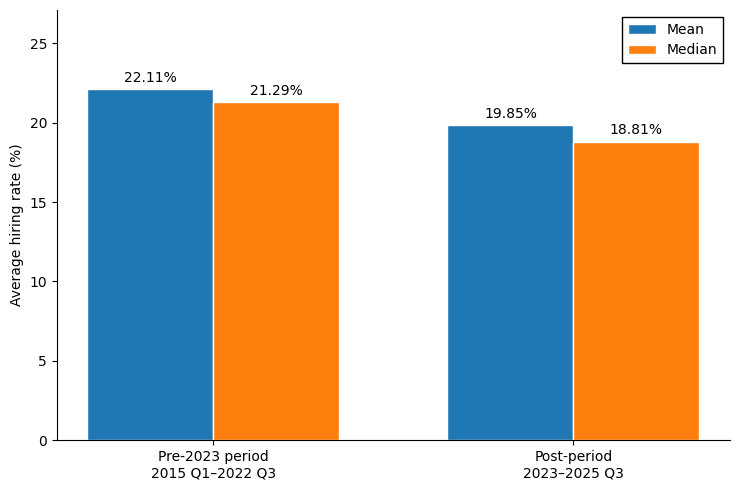

**Fig. 2. Mean and Median Early-Career Hiring Rates Declined After 2022.**

In [18]:
hiring_plot_data = pd.DataFrame(
    {
        "period": [
            "Pre-2023 period\n2015 Q1–2022 Q3",
            "Post-period\n2023–2025 Q3",
        ],
        "mean": [
            descriptive_group_data["pre_hiring_rate_pct"].mean(),
            descriptive_group_data["post_hiring_rate_pct"].mean(),
        ],
        "median": [
            descriptive_group_data["pre_hiring_rate_pct"].median(),
            descriptive_group_data["post_hiring_rate_pct"].median(),
        ],
    }
)

x_positions = np.arange(len(hiring_plot_data))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(7.5, 5))

mean_bars = ax.bar(
    x_positions - bar_width / 2,
    hiring_plot_data["mean"],
    bar_width,
    color="tab:blue",
    edgecolor="white",
    label="Mean",
)

median_bars = ax.bar(
    x_positions + bar_width / 2,
    hiring_plot_data["median"],
    bar_width,
    color="tab:orange",
    edgecolor="white",
    label="Median",
)

ax.bar_label(
    mean_bars,
    labels=[
        f"{value:.2f}%"
        for value in hiring_plot_data["mean"]
    ],
    padding=3,
)

ax.bar_label(
    median_bars,
    labels=[
        f"{value:.2f}%"
        for value in hiring_plot_data["median"]
    ],
    padding=3,
)

ax.set_ylabel("Average hiring rate (%)")
ax.set_xticks(
    x_positions,
    hiring_plot_data["period"],
)
ax.set_ylim(
    0,
    hiring_plot_data["mean"].max() + 5,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

fig.tight_layout()

descriptive_figure_path = (
    project_root
    / "figures"
    / "early_career_hiring_pre_post.png"
)
descriptive_figure_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)
fig.savefig(
    descriptive_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 2. Mean and Median Early-Career Hiring Rates Declined After 2022.**"
    )
)

Across the 3,670 state-industry groups, the mean early-career hiring rate declined from 22.11% during 2015 Q1–2022 Q3 to 19.85% during 2023 Q1–2025 Q3. The median also declined from 21.29% to 18.81%, showing that the overall decrease was not driven only by unusually large hiring rates. Quarterly rates are first averaged within each group, giving every group equal weight in each period, and 2022 Q4 is excluded as a transition quarter. This is an unadjusted descriptive comparison and does not establish that AI exposure caused the decline.

### AI Exposure and the Change in Early-Career Hiring

Because AI exposure varies at the industry level, I average the state-industry hiring-rate changes within each industry before plotting the relationship. Each point therefore represents one of the 80 industries, and each industry receives equal weight. The fitted line summarizes the unadjusted association and is not a causal estimate.

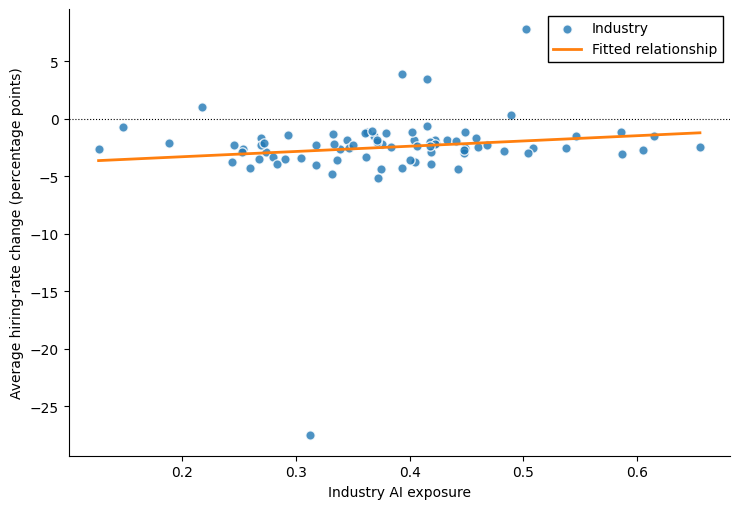

**Fig. 3. AI Exposure Shows Little Unadjusted Relationship with Early-Career Hiring Changes.**

Pearson correlation: 0.14
Spearman correlation: 0.159


,industry,industry_name,ai_exposure,average_hiring_change_pct_points,states
0,482,Rail Transportation,0.312605,-27.522778,3
1,561,Administrative and Support Services,0.371931,-5.151008,49
2,111,Crop Production,0.331394,-4.764707,48
3,211,Oil and Gas Extraction,0.502061,7.798445,24
4,487,Scenic and Sightseeing Transportation,0.393267,3.936168,43
5,486,Pipeline Transportation,0.415528,3.519550,35


In [19]:
# Create one observation per industry
industry_names = (
    primary_analysis_panel[
        ["industry", "industry_name"]
    ]
    .drop_duplicates("industry")
)

industry_descriptive_data = (
    descriptive_group_data
    .groupby("industry", as_index=False)
    .agg(
        ai_exposure=("ai_exposure", "first"),
        average_hiring_change_pct_points=(
            "hiring_change_pct_points",
            "mean",
        ),
        median_hiring_change_pct_points=(
            "hiring_change_pct_points",
            "median",
        ),
        states=("state", "nunique"),
    )
    .merge(
        industry_names,
        on="industry",
        how="left",
        validate="one_to_one",
    )
)

assert len(industry_descriptive_data) == 80


# Summarize the unadjusted association
pearson_correlation = industry_descriptive_data[
    "ai_exposure"
].corr(
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ]
)

spearman_correlation = industry_descriptive_data[
    "ai_exposure"
].corr(
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ],
    method="spearman",
)

line_slope, line_intercept = np.polyfit(
    industry_descriptive_data["ai_exposure"],
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ],
    1,
)

line_x = np.linspace(
    industry_descriptive_data["ai_exposure"].min(),
    industry_descriptive_data["ai_exposure"].max(),
    100,
)
line_y = line_intercept + line_slope * line_x


# Plot the industry-level relationship
fig, ax = plt.subplots(figsize=(7.5, 5.2))

ax.scatter(
    industry_descriptive_data["ai_exposure"],
    industry_descriptive_data[
        "average_hiring_change_pct_points"
    ],
    color="tab:blue",
    edgecolor="white",
    alpha=0.8,
    s=45,
    label="Industry",
)

ax.plot(
    line_x,
    line_y,
    color="tab:orange",
    linewidth=2,
    label="Fitted relationship",
)

ax.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=0.8,
)

ax.set_xlabel("Industry AI exposure")
ax.set_ylabel("Average hiring-rate change (percentage points)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

fig.tight_layout()

ai_hiring_figure_path = (
    project_root
    / "figures"
    / "ai_exposure_hiring_change.png"
)
fig.savefig(
    ai_hiring_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 3. AI Exposure Shows Little Unadjusted Relationship with Early-Career Hiring Changes.**"
    )
)

print(
    "Pearson correlation:",
    round(pearson_correlation, 3),
)
print(
    "Spearman correlation:",
    round(spearman_correlation, 3),
)

industry_change_extremes = pd.concat(
    [
        industry_descriptive_data.nsmallest(
            3,
            "average_hiring_change_pct_points",
        ),
        industry_descriptive_data.nlargest(
            3,
            "average_hiring_change_pct_points",
        ),
    ],
    ignore_index=True,
)

display(
    industry_change_extremes[
        [
            "industry",
            "industry_name",
            "ai_exposure",
            "average_hiring_change_pct_points",
            "states",
        ]
    ]
)

Across the 80 industries, AI exposure had only a weak positive association with the average pre-to-post change in early-career hiring. The Pearson correlation was 0.140 and the Spearman correlation was 0.159. The unadjusted comparison therefore did not show the expected pattern of more AI-exposed industries experiencing larger hiring declines. This does not establish that AI exposure has no relationship with hiring because the comparison does not account for employment adjustment, state differences, common quarterly changes, or the unequal number of states observed within each industry.

### Employment Above Trend and the Change in Early-Career Hiring

Both employment above trend and hiring-rate changes vary at the state-industry level, so this comparison uses all 3,670 eligible groups. Because both variables contain a small number of extreme values, the graph displays the 3,534 observations within their 1st–99th percentile bounds. The full sample remains unchanged and is included in the influence comparison that follows.

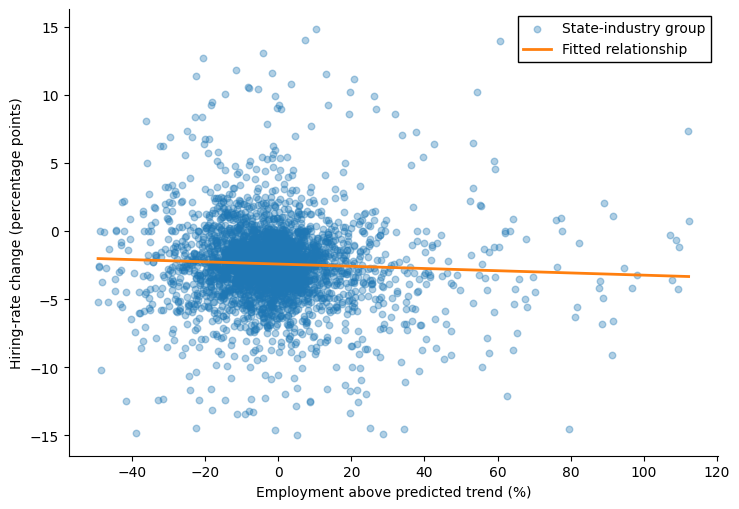

**Fig. 4. Employment Above Trend Shows Little Relationship with Early-Career Hiring Changes.**

Groups in full sample: 3670
Groups displayed: 3534


In [20]:
# Identify the central range for a readable figure
trend_bounds = descriptive_group_data[
    "employment_above_trend_log_pct"
].quantile([0.01, 0.99])

hiring_change_bounds = descriptive_group_data[
    "hiring_change_pct_points"
].quantile([0.01, 0.99])

central_trend_data = descriptive_group_data.loc[
    descriptive_group_data[
        "employment_above_trend_log_pct"
    ].between(trend_bounds.iloc[0], trend_bounds.iloc[1])
    & descriptive_group_data[
        "hiring_change_pct_points"
    ].between(
        hiring_change_bounds.iloc[0],
        hiring_change_bounds.iloc[1],
    )
].copy()

trend_line_slope, trend_line_intercept = np.polyfit(
    central_trend_data["employment_above_trend_log_pct"],
    central_trend_data["hiring_change_pct_points"],
    1,
)

trend_line_x = np.linspace(
    central_trend_data["employment_above_trend_log_pct"].min(),
    central_trend_data["employment_above_trend_log_pct"].max(),
    100,
)
trend_line_y = (
    trend_line_intercept
    + trend_line_slope * trend_line_x
)


# Plot the central observations
fig, ax = plt.subplots(figsize=(7.5, 5.2))

ax.scatter(
    central_trend_data["employment_above_trend_log_pct"],
    central_trend_data["hiring_change_pct_points"],
    color="tab:blue",
    alpha=0.35,
    s=22,
    label="State-industry group",
)

ax.plot(
    trend_line_x,
    trend_line_y,
    color="tab:orange",
    linewidth=2,
    label="Fitted relationship",
)

ax.set_xlabel("Employment above predicted trend (%)")
ax.set_ylabel("Hiring-rate change (percentage points)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

fig.tight_layout()

trend_hiring_figure_path = (
    project_root
    / "figures"
    / "employment_trend_hiring_change.png"
)
fig.savefig(
    trend_hiring_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 4. Employment Above Trend Shows Little Relationship with Early-Career Hiring Changes.**"
    )
)

print("Groups in full sample:", len(descriptive_group_data))
print("Groups displayed:", len(central_trend_data))

### Check the Influence of Extreme Observations

I compare Pearson and Spearman correlations in the full samples with correlations calculated within the 1st–99th percentile bounds. This is a diagnostic only: observations outside these bounds remain in the primary dataset and will be addressed later through regression sensitivity checks.

In [21]:
# Apply the same percentile diagnostic to the industry relationship
ai_exposure_bounds = industry_descriptive_data[
    "ai_exposure"
].quantile([0.01, 0.99])

industry_change_bounds = industry_descriptive_data[
    "average_hiring_change_pct_points"
].quantile([0.01, 0.99])

central_ai_data = industry_descriptive_data.loc[
    industry_descriptive_data["ai_exposure"].between(
        ai_exposure_bounds.iloc[0],
        ai_exposure_bounds.iloc[1],
    )
    & industry_descriptive_data[
        "average_hiring_change_pct_points"
    ].between(
        industry_change_bounds.iloc[0],
        industry_change_bounds.iloc[1],
    )
].copy()


def association_summary(relationship, sample, data, x, y):
    return {
        "relationship": relationship,
        "sample": sample,
        "observations": len(data),
        "pearson_correlation": data[x].corr(data[y]),
        "spearman_correlation": data[x].corr(
            data[y],
            method="spearman",
        ),
    }


influence_comparison = pd.DataFrame(
    [
        association_summary(
            "AI exposure and hiring change",
            "Full sample",
            industry_descriptive_data,
            "ai_exposure",
            "average_hiring_change_pct_points",
        ),
        association_summary(
            "AI exposure and hiring change",
            "1st–99th percentile bounds",
            central_ai_data,
            "ai_exposure",
            "average_hiring_change_pct_points",
        ),
        association_summary(
            "Employment trend and hiring change",
            "Full sample",
            descriptive_group_data,
            "employment_above_trend_log_pct",
            "hiring_change_pct_points",
        ),
        association_summary(
            "Employment trend and hiring change",
            "1st–99th percentile bounds",
            central_trend_data,
            "employment_above_trend_log_pct",
            "hiring_change_pct_points",
        ),
    ]
)

display(influence_comparison.round(3))

,relationship,sample,observations,pearson_correlation,spearman_correlation
0,AI exposure and hiring change,Full sample,80,0.140,0.159
1,AI exposure and hiring change,1st–99th percentile bounds,76,0.082,0.117
2,Employment trend and hiring change,Full sample,3670,0.024,-0.060
3,Employment trend and hiring change,1st–99th percentile bounds,3534,-0.048,-0.062


Employment above trend had little unadjusted relationship with hiring-rate changes. Its Pearson correlation with hiring change was 0.024 in the full sample and -0.048 within the percentile bounds; the corresponding Spearman correlations were -0.060 and -0.062. The change in the Pearson direction shows that extreme values influenced the fitted linear relationship, but every correlation remained close to zero.

The AI-exposure relationship was also sensitive to extremes but remained weak. Its Pearson correlation declined from 0.140 to 0.082, while its Spearman correlation declined from 0.159 to 0.117. The descriptive evidence therefore did not show a strong relationship between either explanatory measure and hiring changes. All observations remain in the primary sample; the percentile restrictions will be used only as a sensitivity check during modeling.

## Fixed-Effects Panel Analysis

The primary analysis asks whether the change in early-career hiring after 2022 differs with industry AI exposure after accounting for employment above trend. State-industry fixed effects control for stable differences across groups, while quarter fixed effects control for shocks shared across groups in the same quarter, including the pandemic and national labor-market conditions. Standard errors are clustered by industry because AI exposure varies at the industry level.

AI exposure and employment above trend do not change over time within a state-industry group, so their separate levels are absorbed by the state-industry fixed effects. The model therefore uses each measure's interaction with the post-period indicator. The estimates describe associations and are not interpreted as causal effects.

### Prepare the Model Variables

I rescale AI exposure so that its coefficient represents a 0.10 increase in exposure. I also rescale employment above trend so that its coefficient represents a 10-percentage-point increase. This changes only the units of the coefficients, not the estimated relationships.

In [22]:
# Prepare identifiers and readable coefficient units
model_data = primary_analysis_panel.copy()
model_data["state_industry"] = (
    model_data["state"].astype(str)
    + "_"
    + model_data["industry"].astype(str)
)
model_data["ai_exposure_10pp"] = model_data["ai_exposure"] / 0.10
model_data["employment_above_trend_10pp"] = (
    model_data["employment_above_trend_log_pct"] / 10
)

# Create the post-period interactions
model_data["ai_exposure_post"] = (
    model_data["ai_exposure_10pp"] * model_data["post"]
)
model_data["employment_trend_post"] = (
    model_data["employment_above_trend_10pp"]
    * model_data["post"]
)

# Confirm the estimation sample
model_columns = [
    "hiring_rate_pct",
    "ai_exposure_post",
    "employment_trend_post",
    "state_industry",
    "period",
    "industry",
]

assert model_data[model_columns].notna().all().all()
assert model_data["post"].isin([0, 1]).all()
assert not model_data.duplicated(
    ["state_industry", "period"]
).any()
assert model_data.groupby("state_industry")["post"].nunique().eq(2).all()

print("Observations:", f"{len(model_data):,}")
print("State-industry groups:", f"{model_data['state_industry'].nunique():,}")
print("Quarters:", model_data["period"].nunique())
print("Industry clusters:", model_data["industry"].nunique())

Observations: 145,995
State-industry groups: 3,670
Quarters: 42
Industry clusters: 80


### Estimate the Primary Models

The first model estimates the post-period AI-exposure relationship without the employment adjustment measure. The second is the primary specification and adds employment above trend. Comparing the AI coefficient across the two models shows whether accounting for post-pandemic employment adjustment materially changes the estimated relationship. Both models use the same fixed effects and industry-clustered standard errors.

In [23]:
# Model 1: AI exposure interaction only
ai_only_model = feols(
    "hiring_rate_pct ~ ai_exposure_post | state_industry + period",
    data=model_data,
    vcov={"CRV1": "industry"},
)

# Model 2: primary specification with employment adjustment
primary_model = feols(
    (
        "hiring_rate_pct ~ ai_exposure_post + employment_trend_post "
        "| state_industry + period"
    ),
    data=model_data,
    vcov={"CRV1": "industry"},
)

# Display the estimated coefficients and uncertainty
def tidy_model_results(model, model_name):
    results = model.tidy().rename_axis("term").reset_index()
    results.insert(0, "model", model_name)
    return results


model_results = pd.concat(
    [
        tidy_model_results(ai_only_model, "AI exposure only"),
        tidy_model_results(primary_model, "Primary model"),
    ],
    ignore_index=True,
)

display(model_results.round(3))

,model,term,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%
0,AI exposure only,ai_exposure_post,0.080,0.119,0.675,0.502,-0.157,0.317
1,Primary model,ai_exposure_post,0.093,0.120,0.774,0.442,-0.146,0.331
2,Primary model,employment_trend_post,-0.032,0.047,-0.692,0.491,-0.126,0.061


Model 1 estimates the relationship between AI exposure and the post-2022 change in early-career hiring without including employment above trend. The AI-exposure coefficient is 0.080, meaning that a 0.10 increase in AI exposure is associated with a 0.08-percentage-point increase in the hiring rate after 2022. However, the standard error is 0.119, the p-value is 0.502, and the 95% confidence interval ranges from −0.157 to 0.317 percentage points. Because the confidence interval contains zero and the p-value is large, Model 1 does not provide statistically clear evidence of a relationship between AI exposure and the change in hiring.

Model 2 adds employment above the pre-COVID trend. After including this measure, the AI-exposure coefficient increases slightly from 0.080 to 0.093. This means that a 0.10 increase in AI exposure is associated with an estimated 0.093-percentage-point increase in the post-2022 hiring rate. The estimate remains statistically insignificant, with a standard error of 0.120, a p-value of 0.442, and a 95% confidence interval from −0.146 to 0.331 percentage points.

The employment-above-trend coefficient is −0.032. This means that employment being 10 percentage points further above its predicted trend is associated with a 0.032-percentage-point lower hiring rate after 2022. This relationship is also not statistically significant: its p-value is 0.491, and its confidence interval ranges from −0.126 to 0.061 percentage points.

Overall, adding employment above trend does not meaningfully change the AI-exposure estimate. The AI coefficient remains small, slightly positive, and statistically uncertain in both models. Therefore, these results do not support the expectation that industries with greater AI exposure experienced a larger decline in early-career hiring rates after 2022. They also do not show a clear relationship between employment above trend and subsequent hiring rates. These estimates should be interpreted as a lack of statistically clear evidence, rather than proof that the relationships are exactly zero.

### Check the Primary Model

Before interpreting the secondary outcome, I check whether the primary model has unusual fitted values, unequal residual spread, or extreme residuals. The residual-versus-fitted plot examines whether the errors remain centered near zero and whether their spread changes with the predicted hiring rate. The Q-Q plot compares the residual distribution with a normal distribution. These plots are diagnostics rather than tests of statistical significance, and perfectly normal residuals are not required for the industry-clustered inference used here.

,diagnostic,value
0,Mean residual,0.000
1,Residual standard deviation,8.121
2,Residual skewness,2.657
3,Residual excess kurtosis,36.768
4,99th percentile of absolute residuals,31.028
5,Absolute residuals above 50 percentage points,369.000
6,Negative fitted hiring rates,157.000


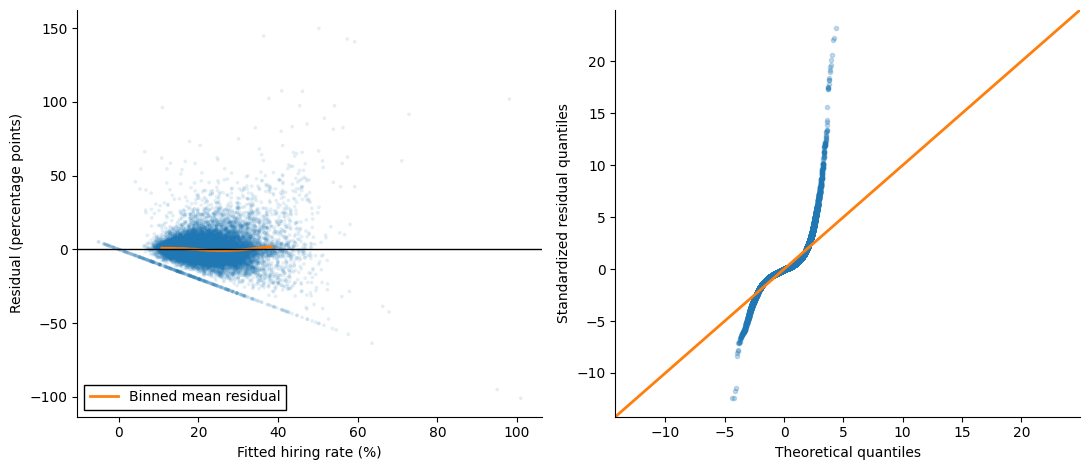

**Fig. 5. Primary-Model Residuals Show Heavy Tails and Increasing Spread.**

In [24]:
# Collect fitted values and residuals
primary_diagnostics = pd.DataFrame(
    {
        "fitted": primary_model.predict(),
        "residual": primary_model.resid(),
    },
    index=model_data.index,
)
primary_diagnostics["absolute_residual"] = (
    primary_diagnostics["residual"].abs()
)

residual_summary = pd.Series(
    {
        "Mean residual": primary_diagnostics["residual"].mean(),
        "Residual standard deviation": primary_diagnostics["residual"].std(),
        "Residual skewness": primary_diagnostics["residual"].skew(),
        "Residual excess kurtosis": primary_diagnostics["residual"].kurt(),
        "99th percentile of absolute residuals": primary_diagnostics["absolute_residual"].quantile(0.99),
        "Absolute residuals above 50 percentage points": primary_diagnostics["absolute_residual"].gt(50).sum(),
        "Negative fitted hiring rates": primary_diagnostics["fitted"].lt(0).sum(),
    },
    name="value",
).rename_axis("diagnostic").reset_index()

display(residual_summary.round(3))

# Calculate the mean residual across fitted-value bins
primary_diagnostics["fitted_bin"] = pd.qcut(
    primary_diagnostics["fitted"],
    20,
    duplicates="drop",
)
binned_residuals = (
    primary_diagnostics
    .groupby("fitted_bin", observed=True)
    .agg(
        fitted_mean=("fitted", "mean"),
        residual_mean=("residual", "mean"),
    )
    .reset_index(drop=True)
)

# Sample points only for a readable scatter plot
diagnostic_sample = primary_diagnostics.sample(
    n=min(30_000, len(primary_diagnostics)),
    random_state=401,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

axes[0].scatter(
    diagnostic_sample["fitted"],
    diagnostic_sample["residual"],
    color="tab:blue",
    s=7,
    alpha=0.12,
    edgecolors="none",
    rasterized=True,
)
axes[0].plot(
    binned_residuals["fitted_mean"],
    binned_residuals["residual_mean"],
    color="tab:orange",
    linewidth=2,
    label="Binned mean residual",
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Fitted hiring rate (%)")
axes[0].set_ylabel("Residual (percentage points)")
axes[0].legend(
    frameon=True,
    fancybox=False,
    framealpha=1,
    edgecolor="black",
    facecolor="white",
)

qqplot(
    primary_diagnostics["residual"],
    line="45",
    fit=True,
    ax=axes[1],
    marker=".",
    markerfacecolor="tab:blue",
    markeredgecolor="tab:blue",
    alpha=0.25,
)
axes[1].get_lines()[1].set_color("tab:orange")
axes[1].get_lines()[1].set_linewidth(2)
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Standardized residual quantiles")

for axis in axes:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

fig.tight_layout()

diagnostic_figure_path = (
    project_root / "figures" / "primary_model_diagnostics.png"
)
fig.savefig(
    diagnostic_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
display(
    Markdown(
        "**Fig. 5. Primary-Model Residuals Show Heavy Tails and Increasing Spread.**"
    )
)

The residual-versus-fitted plot shows that the errors remain reasonably close to zero through most of the fitted range, although the spread becomes wider for groups with higher predicted hiring rates. The binned mean residual stays within approximately two percentage points of zero, suggesting only modest systematic curvature. The linear model produces 157 negative fitted rates, representing about 0.1% of the sample, so invalid predictions are rare rather than a general model problem.

The Q-Q plot is expected to depart from the reference line in the tails. The residual skewness is 2.657 and excess kurtosis is 36.768, while 369 observations have absolute residuals greater than 50 percentage points. This reflects the small state-industry cells that can have unusually high published hiring rates. The heavy tails and unequal spread justify the use of cluster-robust standard errors, but they also make an outlier-sensitivity check important. The Q-Q plot does not determine whether the AI coefficient is statistically significant and does not replace the later event-study assessment of pre-existing trends.

### Check Sensitivity to Extreme Observations

I re-estimate the primary model after excluding the largest 1% of absolute residuals and, separately, observations outside the 1st-99th percentile range of the employment-above-trend measure. These restrictions are diagnostic checks only; the full published sample remains the primary specification.

In [25]:
# Exclude the largest 1% of absolute residuals
absolute_residual_cutoff = primary_diagnostics[
    "absolute_residual"
].quantile(0.99)
central_residual_data = model_data.loc[
    primary_diagnostics["absolute_residual"].le(
        absolute_residual_cutoff
    )
].copy()

residual_sensitivity_model = feols(
    (
        "hiring_rate_pct ~ ai_exposure_post + employment_trend_post "
        "| state_industry + period"
    ),
    data=central_residual_data,
    vcov={"CRV1": "industry"},
)

# Exclude the tails of the employment-trend measure
employment_trend_bounds = model_data[
    "employment_above_trend_log_pct"
].quantile([0.01, 0.99])
central_employment_trend_data = model_data.loc[
    model_data["employment_above_trend_log_pct"].between(
        employment_trend_bounds.iloc[0],
        employment_trend_bounds.iloc[1],
    )
].copy()

employment_trend_sensitivity_model = feols(
    (
        "hiring_rate_pct ~ ai_exposure_post + employment_trend_post "
        "| state_industry + period"
    ),
    data=central_employment_trend_data,
    vcov={"CRV1": "industry"},
)

outlier_sensitivity_results = pd.concat(
    [
        tidy_model_results(primary_model, "Full primary sample"),
        tidy_model_results(
            residual_sensitivity_model,
            "Exclude largest 1% of residuals",
        ),
        tidy_model_results(
            employment_trend_sensitivity_model,
            "Exclude employment-trend tails",
        ),
    ],
    ignore_index=True,
)

display(outlier_sensitivity_results.round(3))

/Users/minhvietnguyen/Documents/Fall_26/DA 401/senior-research/.venv/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 3 singleton fixed effect(s) dropped from the model.
  warnings.warn(


,model,term,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%
0,Full primary sample,ai_exposure_post,0.093,0.120,0.774,0.442,-0.146,0.331
1,Full primary sample,employment_trend_post,-0.032,0.047,-0.692,0.491,-0.126,0.061
2,Exclude largest 1% of residuals,ai_exposure_post,0.037,0.118,0.313,0.755,-0.197,0.271
3,Exclude largest 1% of residuals,employment_trend_post,-0.033,0.038,-0.860,0.392,-0.110,0.043
4,Exclude employment-trend tails,ai_exposure_post,0.111,0.121,0.920,0.360,-0.129,0.352
5,Exclude employment-trend tails,employment_trend_post,-0.106,0.066,-1.596,0.114,-0.237,0.026


The AI-exposure estimate decreases from 0.093 in the full sample to 0.037 after excluding the largest 1% of absolute residuals, but it remains statistically insignificant (`p = 0.755`). Excluding the tails of the employment-above-trend measure produces an AI estimate of 0.111, which is also insignificant (`p = 0.360`). The employment-above-trend interaction remains statistically insignificant in both checks. Extreme observations therefore affect the exact coefficient sizes but do not produce the primary conclusion. Across all three specifications, there is no statistically clear relationship between AI exposure and the post-2022 change in the early-career hiring rate.

### Secondary Outcome: Number of Hires

The primary outcome remains the hiring rate. As a secondary analysis, I estimate the same fixed-effects specification using the natural logarithm of `HirAEnd`, the number of hires that remain employed at the end of the quarter. This distinguishes a change in hiring activity from a change in the rate caused by a changing employment denominator.

A regular logarithm is undefined for zero counts, so this model uses observations with at least one hire and reports the number excluded. State-industry groups with only one positive-count observation are also removed because they cannot contribute within-group variation. The AI coefficient is converted to a percentage change associated with a 0.10 increase in exposure. The model retains the employment-above-trend interaction, state-industry fixed effects, quarter fixed effects, and industry-clustered standard errors.

In [26]:
# Keep positive hire counts for the logarithmic outcome
assert model_data["hire_count"].notna().all()
positive_hire_count_data = model_data.loc[
    model_data["hire_count"].gt(0)
].copy()
positive_hire_count_data["log_hire_count"] = np.log(
    positive_hire_count_data["hire_count"]
)
positive_observations_by_group = (
    positive_hire_count_data
    .groupby("state_industry")["log_hire_count"]
    .transform("size")
)
hire_count_model_data = positive_hire_count_data.loc[
    positive_observations_by_group.gt(1)
].copy()

print("Primary-panel observations:", f"{len(model_data):,}")
print(
    "Zero hire-count observations excluded:",
    f"{model_data['hire_count'].eq(0).sum():,}",
)
print(
    "Singleton observations excluded:",
    f"{positive_observations_by_group.eq(1).sum():,}",
)
print("Model observations:", f"{len(hire_count_model_data):,}")

# Estimate the secondary-outcome model
secondary_hire_model = feols(
    (
        "log_hire_count ~ ai_exposure_post + employment_trend_post "
        "| state_industry + period"
    ),
    data=hire_count_model_data,
    vcov={"CRV1": "industry"},
)

secondary_hire_results = tidy_model_results(
    secondary_hire_model,
    "Secondary hire-count model",
)
secondary_hire_results["percent_change"] = (
    np.expm1(secondary_hire_results["Estimate"]) * 100
)

display(secondary_hire_results.round(3))

Primary-panel observations: 145,995
Zero hire-count observations excluded: 2,333
Singleton observations excluded: 14
Model observations: 143,648


,model,term,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,percent_change
0,Secondary hire-count model,ai_exposure_post,-0.034,0.019,-1.749,0.084,-0.072,0.005,-3.312
1,Secondary hire-count model,employment_trend_post,0.014,0.010,1.428,0.157,-0.006,0.034,1.429
